# Практическая работа 1. Международные туристские поездки

Рассмотрим, как распределены туристские поездки между 68 странами и территориями в 2024 году. Данные за 2023 год нужны для дополнительного сравнения.

Источник: [UN Tourism, Inbound Tourism](https://www.untourism.int/tourism-statistics/tourism-data-inbound-tourism), [официальная выгрузка XLSX](https://pre-webunwto.s3.eu-west-1.amazonaws.com/s3fs-public/2026-09/UN_Tourism_inbound_arrivals_09_2026.xlsx). Показатель `INBD_TRIP_TOTL_TOTL_TOUR`, партнёр `World`. Это поездки с ночёвкой, а не число уникальных туристов.


In [3]:
from io import StringIO
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# Исходные данные взяты из официальной выгрузки UN Tourism.
csv_data = """country,arrivals_2023_thousand,arrivals_2024_thousand,flag_2023,flag_2024
Albania,9741,11483,,
Andorra,4048.1,4167.6,,
Antigua and Barbuda,281.8,330.2,,
Argentina,7285.688,6603.877,,
Austria,30910.333,32195.289,,
Bahamas,1872.059,1869.133,,
Bahrain,5484,6618,,
Armenia,2316,2208,,
Barbados,636.0459,704.34,,
Belgium,9280,9638,,
Bosnia and Herzegovina,1198,1388.775,,
Brazil,5908.341,6773.619,,
Myanmar,1067,808,E,E
Canada,18344,19913,,
Chile,3730.507,5239.233,,
Taiwan Province of China,6487,7858,,
Costa Rica,2751.134,2919.483,,
Cyprus,3845.652,4040.2,,
Dominican Republic,8058.67127402904,8535.70072276276,,
El Salvador,2479.09956037024,3186.98854016912,,
Ethiopia,247,536,,
Fiji,929.74,928.938,,
Finland,4248,4475,E,
French Guiana,77,86,,
Georgia,4669,5092,,
Germany,34712,37420,,
Guam,656.518,739.146,,
"China, Hong Kong Special Administrative Region",17159.3,21943.9,,B
Hungary,12933,13155,,
India,18783,20442,,
Indonesia,11382,13603,,
Israel,3010,961,,
Italy,57250,57725,,
Japan,25066,36870,,
Kazakhstan,9871.166,10381.566,,
Jordan,5346,5217,,
Republic of Korea,11032,16370,,
Liechtenstein,114.399,117.789,,
Lithuania,2404.7,2383.3,,
"China, Macao Special Administrative Region",14227.229,16043.768,,
Malta,2981.5,3563.6,,
Mauritius,1295,1382,,
Mexico,41949.428,45038.754,,
Monaco,341.248,348.258,,
Mongolia,594,727,,
Republic of Moldova,195.447,254.02,,
Oman,2849.06025889549,2659.00147033525,,
New Caledonia,125.097,59.399,,
New Zealand,2827.557,3175.839,,
Nigeria,528.36,538.9272,,
Paraguay,864,1061,,
Poland,18987,19723,,
Portugal,26504,28970,E,E
Puerto Rico,5046.2,5551.2,,
Romania,14777,13353,,
Saudi Arabia,27423.536,29727.443,,
Serbia,2134.305,2384.735,,
Singapore,10812,13025,,
Slovenia,4658,5054,,
South Africa,8483,8919,,
Spain,85169.05,93759.297,,
Trinidad and Tobago,309,334,,
Ukraine,2346,2482,,
North Macedonia,734.139,830.179,,
United Kingdom of Great Britain and Northern Ireland,37214.8047217239,38229.567894179,,
United States of America,66349.859,72390.321,,
Burkina Faso,121,132,,
Uzbekistan,6626.302,7957.213,,
"""

data = pd.read_csv(StringIO(csv_data), float_precision="round_trip")
data[["flag_2023", "flag_2024"]] = data[["flag_2023", "flag_2024"]].fillna("")
print(data.head().to_string(index=False))


            country  arrivals_2023_thousand  arrivals_2024_thousand flag_2023 flag_2024
            Albania                9741.000               11483.000                    
            Andorra                4048.100                4167.600                    
Antigua and Barbuda                 281.800                 330.200                    
          Argentina                7285.688                6603.877                    
            Austria               30910.333               32195.289                    


## Подготовка и основные показатели

Переведём значения в миллионы поездок. Проверим пропуски, повторяющиеся территории и положительность. Среднее и исправленная дисперсия считаются по обычным формулам, у дисперсии знаменатель равен n − 1. Коэффициент вариации — отношение стандартного отклонения к среднему в процентах.

In [4]:
# Все дальнейшие расчёты — в миллионах поездок.
data["arrivals_2023"] = data["arrivals_2023_thousand"] / 1000
data["arrivals_2024"] = data["arrivals_2024_thousand"] / 1000

assert len(data) == 68
assert data["country"].is_unique
assert data[["arrivals_2023", "arrivals_2024"]].notna().all().all()
assert (data[["arrivals_2023", "arrivals_2024"]] > 0).all().all()

arrivals_2024 = data["arrivals_2024"].to_numpy()
log_arrivals = np.log(arrivals_2024)
data["log_arrivals"] = log_arrivals
n = len(arrivals_2024)

mean = arrivals_2024.mean()
median = np.median(arrivals_2024)
variance = arrivals_2024.var(ddof=1)
std = arrivals_2024.std(ddof=1)
cv = std / mean * 100
q1, q3 = np.quantile(arrivals_2024, [0.25, 0.75])
iqr = q3 - q1

characteristics = pd.Series(
    [n, arrivals_2024.sum(), mean, median, variance, std, cv,
     arrivals_2024.min(), arrivals_2024.max(), q1, q3, iqr],
    index=["Число территорий", "Сумма, млн", "Среднее, млн", "Медиана, млн",
           "Дисперсия, млн²", "Стандартное отклонение, млн", "Коэффициент вариации, %",
           "Минимум, млн", "Максимум, млн", "Q1, млн", "Q3, млн", "IQR, млн"],
    name="Значение"
)
print(characteristics.to_string(float_format="{:.6f}".format))

prepared = data[["country", "arrivals_2024", "log_arrivals"]].sort_values("arrivals_2024")
print("\nНачало и конец вариационного ряда:")
print(pd.concat([prepared.head(3), prepared.tail(3)]).to_string(index=False))


Число территорий               68.000000
Сумма, млн                    802.600600
Среднее, млн                   11.802950
Медиана, млн                    5.073000
Дисперсия, млн²               310.968554
Стандартное отклонение, млн    17.634300
Коэффициент вариации, %       149.405873
Минимум, млн                    0.059399
Максимум, млн                  93.759297
Q1, млн                         1.036000
Q3, млн                        13.415500
IQR, млн                       12.379500

Начало и конец вариационного ряда:
                 country  arrivals_2024  log_arrivals
           New Caledonia       0.059399     -2.823478
           French Guiana       0.086000     -2.453408
           Liechtenstein       0.117789     -2.138860
                   Italy      57.725000      4.055690
United States of America      72.390321      4.282073
                   Spain      93.759297      4.540731


## Квартили и крупные значения

Верхняя граница Тьюки равна Q3 + 1,5IQR. Значения за этой границей считаем выбросами для описания распределения. Они остаются в основном расчёте: большой туристский поток сам по себе не означает ошибку.

In [5]:
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr
is_outlier = (data["arrivals_2024"] < lower_limit) | (data["arrivals_2024"] > upper_limit)
outliers = data.loc[is_outlier, ["country", "arrivals_2024"]]

print(f"Границы Тьюки: {lower_limit:.5f}; {upper_limit:.5f} млн")
print(f"Число выбросов: {len(outliers)}")
print(outliers.to_string(index=False))

class_edges = [-np.inf, 1, 3, 7, 15, 35, np.inf]
class_counts = np.histogram(arrivals_2024, bins=class_edges)[0]
classes = pd.DataFrame({
    "Интервал, млн": ["до 1", "1–3", "3–7", "7–15", "15–35", "от 35"],
    "Число территорий": class_counts,
    "Доля, %": class_counts / n * 100
})
print("\nРаспределение по группам:")
print(classes.to_string(index=False))


Границы Тьюки: -17.53325; 31.98475 млн
Число выбросов: 8
                                             country  arrivals_2024
                                             Austria      32.195289
                                             Germany      37.420000
                                               Italy      57.725000
                                               Japan      36.870000
                                              Mexico      45.038754
                                               Spain      93.759297
United Kingdom of Great Britain and Northern Ireland      38.229568
                            United States of America      72.390321

Распределение по группам:
Интервал, млн  Число территорий   Доля, %
         до 1                17 25.000000
          1–3                10 14.705882
          3–7                14 20.588235
         7–15                11 16.176471
        15–35                 9 13.235294
        от 35                 7 10.294118


## Плотность и критерий Пирсона

Сначала сравним гистограммы с 6 и 12 интервалами на одном диапазоне. Затем проверим логнормальную и нормальную модели. В критерии Пирсона границы фиксированы. Для нормальной модели первые два класса объединены, чтобы все ожидаемые частоты были не меньше 5. Число степеней свободы равно k - 1 - 2, так как оценены два параметра.

p по распределению χ² здесь приближённое: параметры найдены по исходным, а не сгруппированным наблюдениям. Ниже дополнительно проверим результат случайными выборками.

In [6]:
mu = log_arrivals.mean()
sigma = log_arrivals.std(ddof=0)
normal_std = arrivals_2024.std(ddof=0)
log_edges = np.array([-np.inf, 1, 3, 7, 15, 35, np.inf])
normal_edges = np.array([-np.inf, 3, 7, 15, 35, np.inf])

# Одна и та же функция нужна для исходных и случайных выборок.
def pearson(values, edges, model):
    if model == "lognormal":
        logs = np.log(values)
        mu_fit = logs.mean()
        sigma_fit = logs.std(ddof=0)
        probabilities = stats.lognorm.cdf(edges, sigma_fit, scale=np.exp(mu_fit))
    else:
        mean_fit = values.mean()
        std_fit = values.std(ddof=0)
        probabilities = stats.norm.cdf(edges, loc=mean_fit, scale=std_fit)

    observed = np.histogram(values, bins=edges)[0]
    expected = len(values) * np.diff(probabilities)
    statistic = np.sum((observed - expected) ** 2 / expected)
    return statistic, observed, expected



### Расчёт критерия Пирсона

Проверим ожидаемые частоты и получим приближённые p-значения для обеих моделей.

In [7]:
chi_log, observed_log, expected_log = pearson(arrivals_2024, log_edges, "lognormal")
chi_normal, observed_normal, expected_normal = pearson(arrivals_2024, normal_edges, "normal")
assert expected_log.min() >= 5
assert expected_normal.min() >= 5

df_log = len(observed_log) - 1 - 2
df_normal = len(observed_normal) - 1 - 2
p_log = stats.chi2.sf(chi_log, df_log)
p_normal = stats.chi2.sf(chi_normal, df_normal)

frequency_table = pd.DataFrame({
    "Интервал, млн": ["до 1", "1–3", "3–7", "7–15", "15–35", "от 35"],
    "Наблюдаемая частота": observed_log,
    "Ожидаемая частота": expected_log
})
print(f"Параметры логарифмов: mu = {mu:.6f}, sigma = {sigma:.6f}")
print(frequency_table.to_string(index=False))
print(f"\nЛогнормальная модель: χ² = {chi_log:.6f}, df = {df_log}, p ≈ {p_log:.6f}")
print(f"Нормальная модель: χ² = {chi_normal:.6f}, df = {df_normal}, p ≈ {p_normal:.8f}")



Параметры логарифмов: mu = 1.370526, sigma = 1.713611
Интервал, млн  Наблюдаемая частота  Ожидаемая частота
         до 1                   17          14.410338
          1–3                   10          15.303005
          3–7                   14          13.227219
         7–15                   11          10.266740
        15–35                    9           7.913955
        от 35                    7           6.878744

Логнормальная модель: χ² = 2.551750, df = 3, p ≈ 0.466011
Нормальная модель: χ² = 22.218592, df = 2, p ≈ 0.00001497


### Гистограммы

Сравним две группировки исходных данных и отдельно посмотрим на логарифмы.

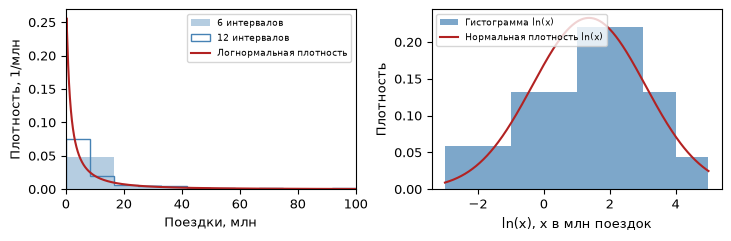

In [8]:
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9})
fig1, axes = plt.subplots(1, 2, figsize=(7.2, 2.3), layout="constrained")
axes[0].hist(arrivals_2024, bins=np.linspace(0, 100, 7), density=True,
             alpha=0.4, color="steelblue", label="6 интервалов")
axes[0].hist(arrivals_2024, bins=np.linspace(0, 100, 13), density=True,
             histtype="step", color="steelblue", label="12 интервалов")
grid = np.linspace(0.02, 100, 2000)
axes[0].plot(grid, stats.lognorm.pdf(grid, sigma, scale=np.exp(mu)),
             color="firebrick", label="Логнормальная плотность")
axes[0].set(xlabel="Поездки, млн", ylabel="Плотность, 1/млн", xlim=(0, 100))
axes[0].legend(fontsize=6.8)

log_bins = np.linspace(np.floor(log_arrivals.min()), np.ceil(log_arrivals.max()), 9)
axes[1].hist(log_arrivals, bins=log_bins, density=True, alpha=0.7,
             color="steelblue", label="Гистограмма ln(x)")
log_grid = np.linspace(log_bins[0], log_bins[-1], 500)
axes[1].plot(log_grid, stats.norm.pdf(log_grid, mu, sigma),
             color="firebrick", label="Нормальная плотность ln(x)")
axes[1].set(xlabel="ln(x), x в млн поездок", ylabel="Плотность")
axes[1].legend(fontsize=6.5, loc="upper left")
plt.show()


## Доверительные интервалы

Повторим расчёт на 20 000 выборок с возвращением из исходных 68 значений. Границы 95% интервала - квантили 0,025 и 0,975 полученных оценок. Для этого способа не нужна нормальность исходных данных.

Найдём интервалы среднего, медианы и дисперсии. Они условны по доступным территориям и не исправляют неполное и неслучайное покрытие источника.

In [9]:
repeats = 20000
rng = np.random.default_rng(20261017)
boot_mean = np.zeros(repeats)
boot_median = np.zeros(repeats)
boot_variance = np.zeros(repeats)

# Повторяем расчёт на случайных выборках.
for i in range(repeats):
    sample = rng.choice(arrivals_2024, size=n, replace=True)
    boot_mean[i] = sample.mean()
    boot_median[i] = np.median(sample)
    boot_variance[i] = sample.var(ddof=1)

ci_mean = np.quantile(boot_mean, [0.025, 0.975])
ci_median = np.quantile(boot_median, [0.025, 0.975])
ci_variance = np.quantile(boot_variance, [0.025, 0.975])
bootstrap_intervals = pd.DataFrame(
    [ci_mean, ci_median, ci_variance],
    index=["Среднее, млн", "Медиана, млн", "Дисперсия, млн²"],
    columns=["Нижняя граница", "Верхняя граница"]
)
print("95% bootstrap-интервалы:")
print(bootstrap_intervals.to_string(float_format="{:.6f}".format))


95% bootstrap-интервалы:
                 Нижняя граница  Верхняя граница
Среднее, млн           7.980668        16.313423
Медиана, млн           2.789242         7.907606
Дисперсия, млн²      114.646342       555.858870


## Проверка p-значений случайными выборками

Создадим 10 000 выборок из каждой подобранной модели. В каждой выборке заново оценим параметры и посчитаем критерий Пирсона с прежними границами. p-значение - доля повторов, где статистика не меньше наблюдаемой, с поправкой (число + 1) / (повторы + 1).

При p < 0,05 модель отвергается. Если p ≥ 0,05, данных недостаточно для её отклонения, но это не доказывает модель.

In [10]:
mc_repeats = 10000
mc_rng = np.random.default_rng(20261018)
greater_log = 0
greater_normal = 0

# Параметры заново оцениваются внутри функции pearson.
for i in range(mc_repeats):
    sample = mc_rng.lognormal(mu, sigma, size=n)
    chi_sample, observed, expected = pearson(sample, log_edges, "lognormal")
    if chi_sample >= chi_log:
        greater_log += 1

# Используем тот же генератор дальше, как в исходном расчёте.
for i in range(mc_repeats):
    sample = mc_rng.normal(mean, normal_std, size=n)
    chi_sample, observed, expected = pearson(sample, normal_edges, "normal")
    if chi_sample >= chi_normal:
        greater_normal += 1

p_mc_log = (greater_log + 1) / (mc_repeats + 1)
p_mc_normal = (greater_normal + 1) / (mc_repeats + 1)
print(f"Логнормальная модель: bootstrap p = {p_mc_log:.6f}")
print(f"Нормальная модель: bootstrap p = {p_mc_normal:.6f}")
print("При α = 0,05 нормальная модель отвергается, логнормальная не отвергается.")


Логнормальная модель: bootstrap p = 0.570843
Нормальная модель: bootstrap p = 0.000200
При α = 0,05 нормальная модель отвергается, логнормальная не отвергается.


## Сравнение с 2023 годом и вывод

Сравним одинаковые территории. Гонконг исключим только из сравнения двух лет: флаг B связан с изменением основы учёта в 2024 году. Останутся 67 территорий. Дополнительно посмотрим, насколько среднее зависит от записей с флагами и восьми крупных значений.

Основной срез остаётся поперечным: наблюдения - территории в одном году. Полученные суммы и выводы относятся к доступным данным, а не ко всему миру.

In [11]:
# Флаг B исключаем только из сравнения двух лет.
paired = data.loc[(data["flag_2023"] != "B") & (data["flag_2024"] != "B")].copy()
assert len(paired) == 67
paired_2023 = paired["arrivals_2023"].to_numpy()
paired_2024 = paired["arrivals_2024"].to_numpy()
growth = (paired_2024 / paired_2023 - 1) * 100
total_growth = (paired_2024.sum() / paired_2023.sum() - 1) * 100
median_growth = np.median(growth)
increased = np.sum(paired_2024 > paired_2023)
decreased = np.sum(paired_2024 < paired_2023)
equal = np.sum(paired_2024 == paired_2023)

comparison = pd.DataFrame(
    [[paired_2023.sum(), paired_2024.sum()],
     [paired_2023.mean(), paired_2024.mean()],
     [np.median(paired_2023), np.median(paired_2024)],
     [paired_2023.std(ddof=1), paired_2024.std(ddof=1)]],
    index=["Сумма, млн", "Среднее, млн", "Медиана, млн", "Стандартное отклонение, млн"],
    columns=["2023", "2024"]
)
print(comparison.to_string(float_format="{:.6f}".format))
print(f"\nРост суммы: {total_growth:.4f}%")
print(f"Медиана индивидуальных темпов роста: {median_growth:.4f}%")
print(f"Рост: {increased}; снижение: {decreased}; без изменения: {equal}.")



                                  2023       2024
Сумма, млн                  714.929076 780.656700
Среднее, млн                 10.670583  11.651593
Медиана, млн                  4.248000   5.054000
Стандартное отклонение, млн  16.311217  17.722832

Рост суммы: 9.1936%
Медиана индивидуальных темпов роста: 8.5015%
Рост: 56; снижение: 11; без изменения: 0.


### Влияние отдельных наблюдений

Проверим, как изменятся среднее и медиана без записей с флагами и без выбросов. Основной расчёт сохраняет все 68 наблюдений.

In [12]:
without_flags = data.loc[data["flag_2024"] == "", "arrivals_2024"].to_numpy()
without_outliers = data.loc[~is_outlier, "arrivals_2024"].to_numpy()
sensitivity = pd.DataFrame(
    [[n, mean, median],
     [len(without_flags), without_flags.mean(), np.median(without_flags)],
     [len(without_outliers), without_outliers.mean(), np.median(without_outliers)]],
    index=["Все наблюдения", "Без записей с флагами", "Без выбросов Тьюки"],
    columns=["Число территорий", "Среднее, млн", "Медиана, млн"]
)
print("\nВлияние отдельных наблюдений:")
print(sensitivity.to_string(float_format="{:.6f}".format))




Влияние отдельных наблюдений:
                       Число территорий  Среднее, млн  Медиана, млн
Все наблюдения                       68     11.802950      5.073000
Без записей с флагами                65     11.551980      5.054000
Без выбросов Тьюки                   60      6.482873      3.801900


### Boxplot и вывод

Покажем исходный срез и два сопоставимых среза. Затем кратко выведем основные результаты.

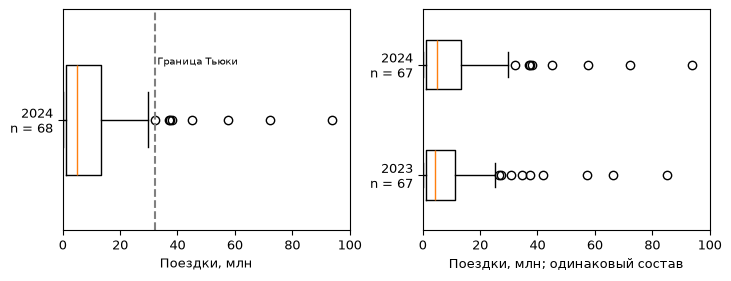


Вывод: среднее 11.803 млн заметно выше медианы 5.073 млн.
Разброс велик: коэффициент вариации 149.41%. Выбросов: 8.
В сопоставимом составе суммарный поток вырос на 9.19%.
Результаты относятся к доступным территориям, а не ко всему миру.


In [13]:
fig2, axes = plt.subplots(1, 2, figsize=(7.2, 2.7), layout="constrained")
axes[0].boxplot([arrivals_2024], orientation="horizontal", widths=0.5)
axes[0].set(yticks=[1], yticklabels=["2024\nn = 68"], xlabel="Поездки, млн", xlim=(0, 100))
axes[0].axvline(upper_limit, color="gray", linestyle="--")
axes[0].text(upper_limit + 1, 1.25, "Граница Тьюки", fontsize=7)
axes[1].boxplot([paired_2023, paired_2024], orientation="horizontal", widths=0.45)
axes[1].set(yticks=[1, 2], yticklabels=["2023\nn = 67", "2024\nn = 67"],
            xlabel="Поездки, млн; одинаковый состав", xlim=(0, 100))
plt.show()

print(f"\nВывод: среднее {mean:.3f} млн заметно выше медианы {median:.3f} млн.")
print(f"Разброс велик: коэффициент вариации {cv:.2f}%. Выбросов: {len(outliers)}.")
print(f"В сопоставимом составе суммарный поток вырос на {total_growth:.2f}%.")
print("Результаты относятся к доступным территориям, а не ко всему миру.")
